In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("netflix_titles.csv")

In [3]:
df

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...
...,...,...,...,...,...,...,...,...,...,...,...,...
8802,s8803,Movie,Zodiac,David Fincher,"Mark Ruffalo, Jake Gyllenhaal, Robert Downey J...",United States,"November 20, 2019",2007,R,158 min,"Cult Movies, Dramas, Thrillers","A political cartoonist, a crime reporter and a..."
8803,s8804,TV Show,Zombie Dumb,NaN,NaN,NaN,"July 1, 2019",2018,TV-Y7,2 Seasons,"Kids' TV, Korean TV Shows, TV Comedies","While living alone in a spooky town, a young g..."
8804,s8805,Movie,Zombieland,Ruben Fleischer,"Jesse Eisenberg, Woody Harrelson, Emma Stone, ...",United States,"November 1, 2019",2009,R,88 min,"Comedies, Horror Movies",Looking to survive in a world taken over by zo...
8805,s8806,Movie,Zoom,Peter Hewitt,"Tim Allen, Courteney Cox, Chevy Chase, Kate Ma...",United States,"January 11, 2020",2006,PG,88 min,"Children & Family Movies, Comedies","Dragged from civilian life, a former superhero..."


In [4]:
# df.shape

In [5]:
# 1 How has the number of netflix title added to the catalog changed over the years. 

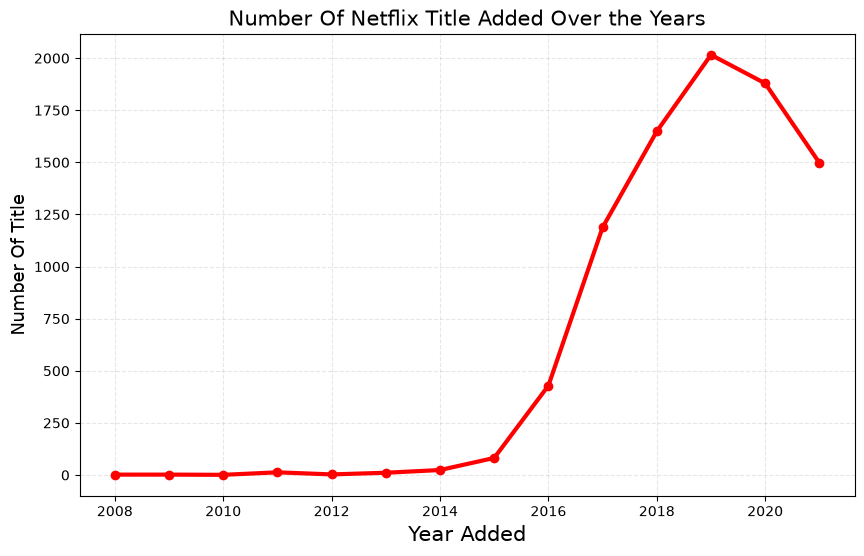

In [6]:
df = pd.read_csv("netflix_titles.csv")
df["date_added"] = pd.to_datetime(df["date_added"].str.strip(), errors="coerce", format="mixed")
df["year_added"] = df["date_added"].dt.year

yearly_counts = df.groupby("year_added")["show_id"].count()
plt.figure(figsize=(10,6))
yearly_counts.plot(kind="line", marker = "o", color="red", linewidth=3)

plt.title("Number Of Netflix Title Added Over the Years", fontsize=15)
plt.xlabel("Year Added", fontsize=15)
plt.ylabel("Number Of Title", fontsize=13)
plt.grid(True, linestyle ="--" ,alpha = 0.3)


In [7]:
# 2 What is the dsitribution of movies vs TV Showes on Netflix?

In [8]:
 movies_tv_shows = df["type"].value_counts().reset_index()

In [9]:
movies_tv_shows

,type,count
0,Movie,6131
1,TV Show,2676


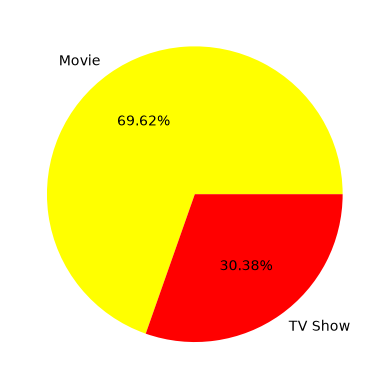

In [10]:
plt.pie(movies_tv_shows["count"], labels=movies_tv_shows["type"], autopct="%.2f%%", colors=["yellow", "red"])

In [11]:
# 3 Whitch countries produce the most Netflix titles?

In [12]:
import matplotlib.pyplot as plt
import pandas as pd

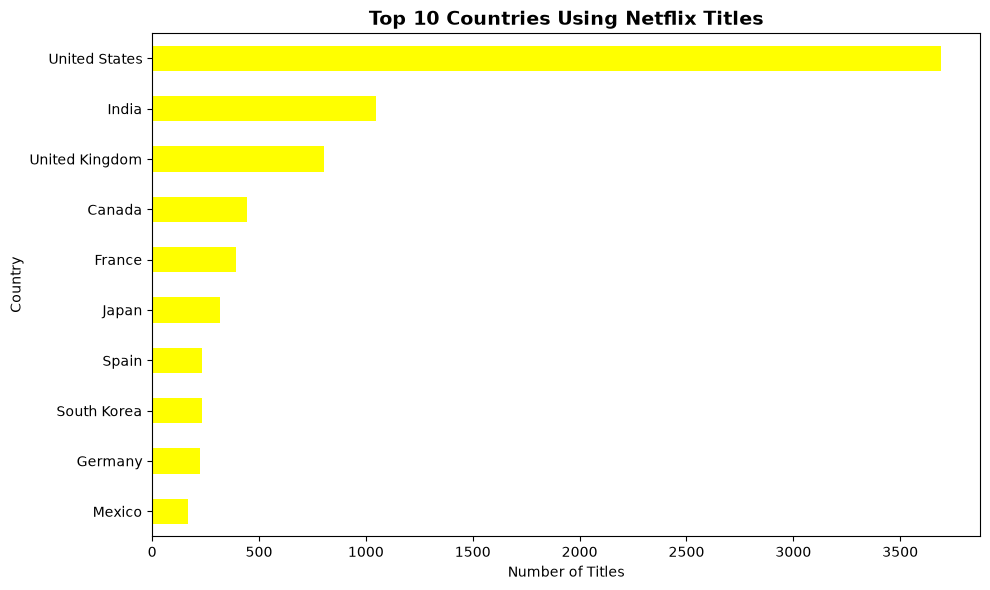

In [13]:
countries = df["country"].dropna().str.split(", ")
exploded_countries = countries.explode()
top_10 = exploded_countries.groupby(exploded_countries).size().nlargest(10)

plt.figure(figsize=(10, 6))
top_10.sort_values().plot(kind="barh", color="yellow")
plt.title("Top 10 Countries Using Netflix Titles", fontsize=14, fontweight="bold")
plt.xlabel("Number of Titles")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

In [14]:
# 4 Which genres/categories have the most titles on Netflix?

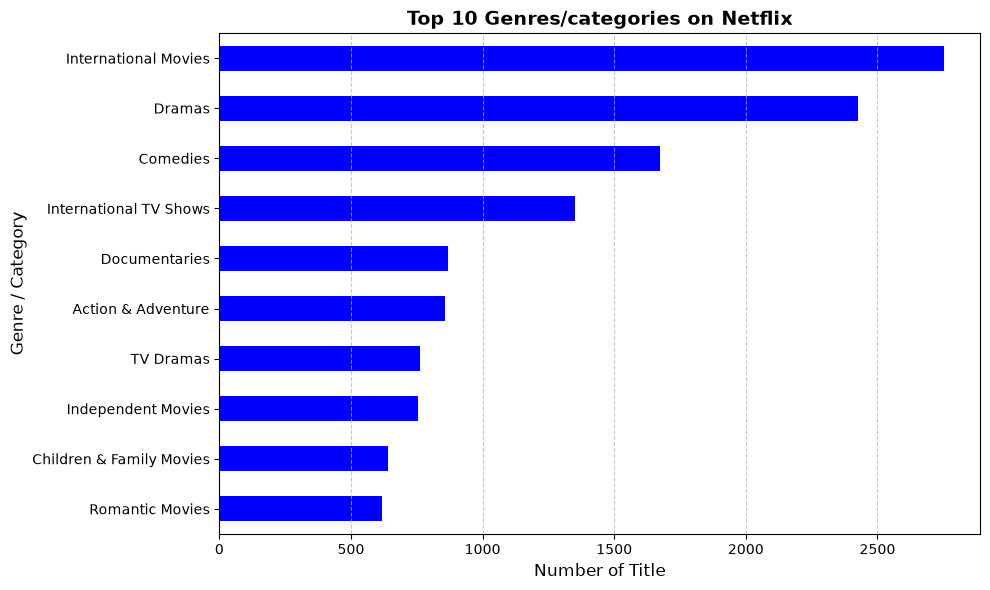

In [15]:

top_genres = (
     df["listed_in"]
     .str.split(",")
     .explode()
     .str.strip()
     .value_counts()
     .head(10)
 )
plt.figure(figsize=(10,6))
top_genres.sort_values(ascending=True).plot(kind="barh", color="blue")

plt.title("Top 10 Genres/categories on Netflix", fontsize=14, fontweight="bold")
plt.xlabel("Number of Title", fontsize=12)
plt.ylabel("Genre / Category", fontsize=12)
plt.grid(axis="x", linestyle="--", alpha=0.7)

plt.tight_layout()
plt.show()

In [16]:
# 5 Which years had the highest number of titles released?
df

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description,year_added
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,2021-09-25,2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm...",2021.0
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t...",2021.0
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...,2021.0
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,2021-09-24,2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo...",2021.0
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...,2021.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
8802,s8803,Movie,Zodiac,David Fincher,"Mark Ruffalo, Jake Gyllenhaal, Robert Downey J...",United States,2019-11-20,2007,R,158 min,"Cult Movies, Dramas, Thrillers","A political cartoonist, a crime reporter and a...",2019.0
8803,s8804,TV Show,Zombie Dumb,NaN,NaN,NaN,2019-07-01,2018,TV-Y7,2 Seasons,"Kids' TV, Korean TV Shows, TV Comedies","While living alone in a spooky town, a young g...",2019.0
8804,s8805,Movie,Zombieland,Ruben Fleischer,"Jesse Eisenberg, Woody Harrelson, Emma Stone, ...",United States,2019-11-01,2009,R,88 min,"Comedies, Horror Movies",Looking to survive in a world taken over by zo...,2019.0
8805,s8806,Movie,Zoom,Peter Hewitt,"Tim Allen, Courteney Cox, Chevy Chase, Kate Ma...",United States,2020-01-11,2006,PG,88 min,"Children & Family Movies, Comedies","Dragged from civilian life, a former superhero...",2020.0


    release_year  total_title_released
70          2018                  1147
69          2017                  1032
71          2019                  1030
72          2020                   953
68          2016                   902
73          2021                   592
67          2015                   560
66          2014                   352
65          2013                   288
64          2012                   237


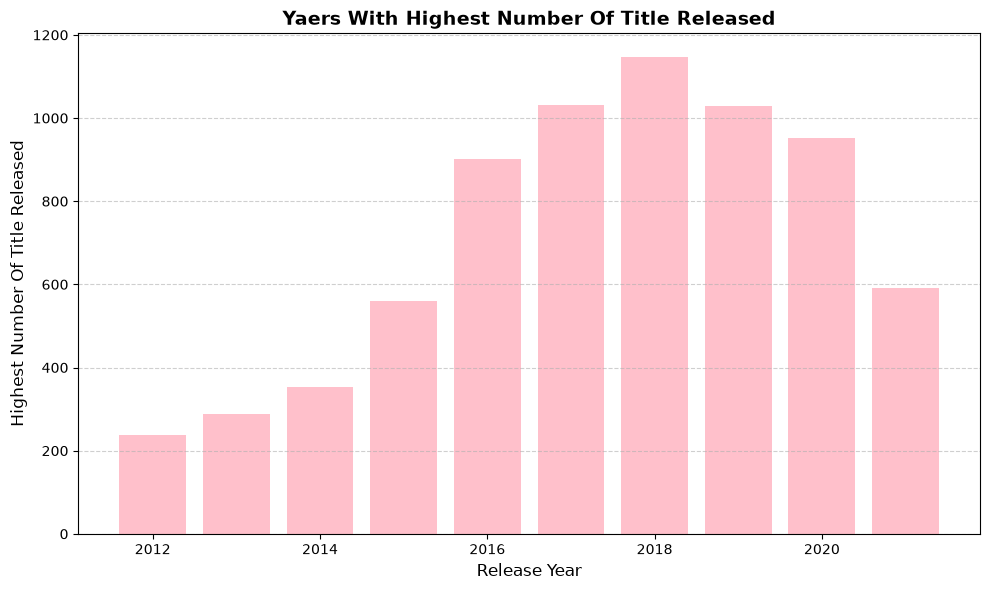

In [17]:
highest_release_years = (
    df.groupby("release_year")
    .agg(total_title_released=("show_id", "count"))
    .reset_index()
    .sort_values(by="total_title_released", ascending=False)
    .head(10)
)
print(highest_release_years)

plt.figure(figsize=(10,6))
plt.bar(
    highest_release_years["release_year"],
    highest_release_years["total_title_released"],
    color="pink"
)

plt.title(
    "Yaers With Highest Number Of Title Released", fontsize=14, fontweight="bold"
)
plt.xlabel("Release Year", fontsize=12)
plt.ylabel("Highest Number Of Title Released", fontsize=12)
plt.grid(axis="y", linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()

In [18]:
# 6 How has Netflix's Movie vs TV Show composition changed over time?

In [19]:
import matplotlib.pyplot as plt
import pandas as pd

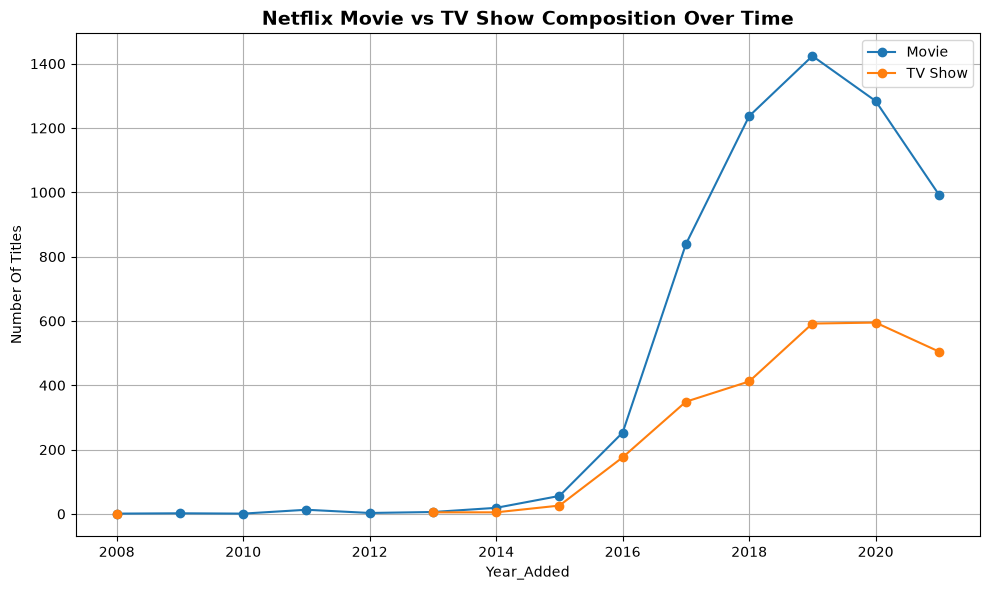

In [20]:
df = pd.read_csv("netflix_titles.csv")
df["date_added"] = pd.to_datetime(df["date_added"].str.strip())
df["year_added"] = df["date_added"].dt.year
composition = df.groupby(["year_added", "type"]).size().unstack()

plt.figure(figsize=(10,6))
plt.plot(composition.index, composition["Movie"], label="Movie", marker="o")
plt.plot(composition.index, composition["TV Show"], label="TV Show", marker="o")
plt.title("Netflix Movie vs TV Show Composition Over Time", fontsize="14", fontweight="bold")
plt.xlabel("Year_Added")
plt.ylabel("Number Of Titles")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [21]:
df.groupby(["year_added", "type"]).size()

year_added  type   
2008.0      Movie         1
            TV Show       1
2009.0      Movie         2
2010.0      Movie         1
2011.0      Movie        13
2012.0      Movie         3
2013.0      Movie         6
            TV Show       5
2014.0      Movie        19
            TV Show       5
2015.0      Movie        56
            TV Show      26
2016.0      Movie       253
            TV Show     176
2017.0      Movie       839
            TV Show     349
2018.0      Movie      1237
            TV Show     412
2019.0      Movie      1424
            TV Show     592
2020.0      Movie      1284
            TV Show     595
2021.0      Movie       993
            TV Show     505
dtype: int64

In [22]:
df.groupby(["year_added", "type"]).size().unstack()

type,Movie,TV Show
year_added,,
2008.0,1.0,1.0
2009.0,2.0,NaN
2010.0,1.0,NaN
2011.0,13.0,NaN
2012.0,3.0,NaN
2013.0,6.0,5.0
2014.0,19.0,5.0
2015.0,56.0,26.0
2016.0,253.0,176.0


In [23]:
# 7 What are the most common content ratings on Netflix?

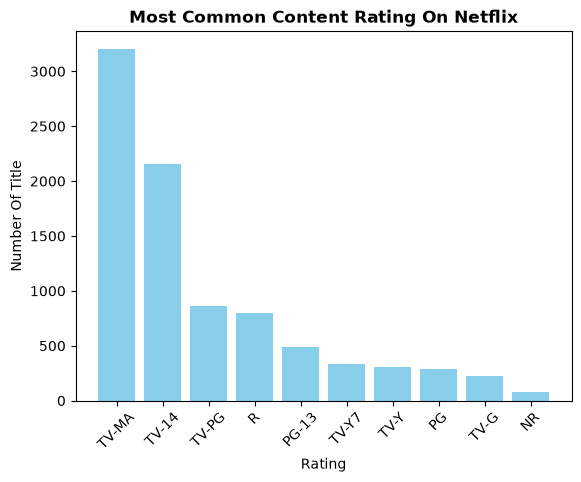

In [24]:
ratings = df["rating"].value_counts().head(10).reset_index()


plt.bar(ratings["rating"], ratings["count"], color="skyblue")
plt.title("Most Common Content Rating On Netflix", fontweight="bold")
plt.ylabel("Number Of Title")
plt.xlabel("Rating")
plt.xticks(rotation=45)

plt.show()

In [25]:
ratings

,rating,count
0,TV-MA,3207
1,TV-14,2160
2,TV-PG,863
3,R,799
4,PG-13,490
5,TV-Y7,334
6,TV-Y,307
7,PG,287
8,TV-G,220
9,NR,80


In [26]:
# 8 How does movie duration vary across Netflix's catalog?

<function matplotlib.pyplot.show(close=None, block=None)>

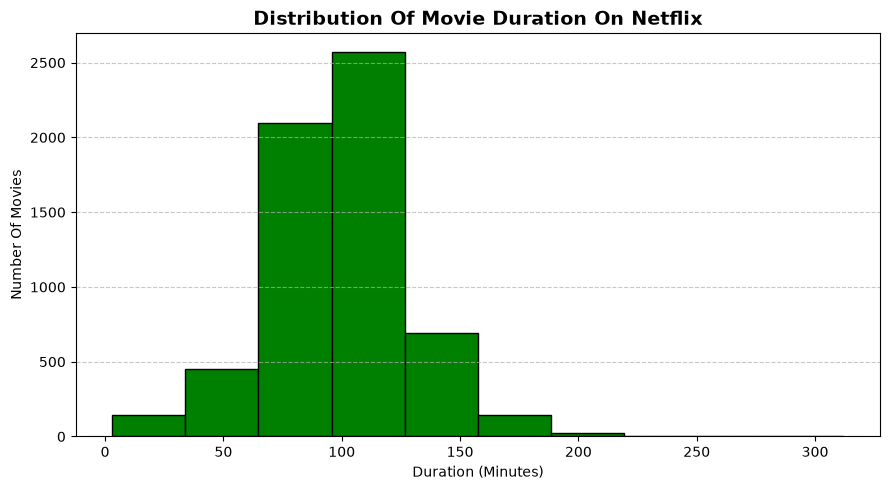

In [27]:
movies = df[df["type"] == "Movie"].copy()
movies["duration_num"] = movies.duration.str.split().str[0]
movies["duration_num"] = movies["duration_num"].astype("float", errors="ignore")
plt.figure(figsize=(9, 5))
plt.hist(movies["duration_num"].dropna(), bins=10, color="green", edgecolor="black")
plt.title("Distribution Of Movie Duration On Netflix", fontsize=14, fontweight="bold")
plt.xlabel("Duration (Minutes)")
plt.ylabel("Number Of Movies")


plt.tight_layout()
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.show




In [28]:
movies

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description,year_added,duration_num
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,2021-09-25,2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm...",2021.0,90.0
6,s7,Movie,My Little Pony: A New Generation,"Robert Cullen, José Luis Ucha","Vanessa Hudgens, Kimiko Glenn, James Marsden, ...",NaN,2021-09-24,2021,PG,91 min,Children & Family Movies,Equestria's divided. But a bright-eyed hero be...,2021.0,91.0
7,s8,Movie,Sankofa,Haile Gerima,"Kofi Ghanaba, Oyafunmike Ogunlano, Alexandra D...","United States, Ghana, Burkina Faso, United Kin...",2021-09-24,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies","On a photo shoot in Ghana, an American model s...",2021.0,125.0
9,s10,Movie,The Starling,Theodore Melfi,"Melissa McCarthy, Chris O'Dowd, Kevin Kline, T...",United States,2021-09-24,2021,PG-13,104 min,"Comedies, Dramas",A woman adjusting to life after a loss contend...,2021.0,104.0
12,s13,Movie,Je Suis Karl,Christian Schwochow,"Luna Wedler, Jannis Niewöhner, Milan Peschel, ...","Germany, Czech Republic",2021-09-23,2021,TV-MA,127 min,"Dramas, International Movies",After most of her family is murdered in a terr...,2021.0,127.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8801,s8802,Movie,Zinzana,Majid Al Ansari,"Ali Suliman, Saleh Bakri, Yasa, Ali Al-Jabri, ...","United Arab Emirates, Jordan",2016-03-09,2015,TV-MA,96 min,"Dramas, International Movies, Thrillers",Recovering alcoholic Talal wakes up inside a s...,2016.0,96.0
8802,s8803,Movie,Zodiac,David Fincher,"Mark Ruffalo, Jake Gyllenhaal, Robert Downey J...",United States,2019-11-20,2007,R,158 min,"Cult Movies, Dramas, Thrillers","A political cartoonist, a crime reporter and a...",2019.0,158.0
8804,s8805,Movie,Zombieland,Ruben Fleischer,"Jesse Eisenberg, Woody Harrelson, Emma Stone, ...",United States,2019-11-01,2009,R,88 min,"Comedies, Horror Movies",Looking to survive in a world taken over by zo...,2019.0,88.0
8805,s8806,Movie,Zoom,Peter Hewitt,"Tim Allen, Courteney Cox, Chevy Chase, Kate Ma...",United States,2020-01-11,2006,PG,88 min,"Children & Family Movies, Comedies","Dragged from civilian life, a former superhero...",2020.0,88.0


In [29]:
import numpy as np

In [30]:
np.linspace(0, 100, 10, dtype="int")

array([  0,  11,  22,  33,  44,  55,  66,  77,  88, 100])

In [31]:
# 9 What is the relationship between movie release year and duration?

In [32]:
import matplotlib.pyplot as plt
import pandas as pd

<function matplotlib.pyplot.show(close=None, block=None)>

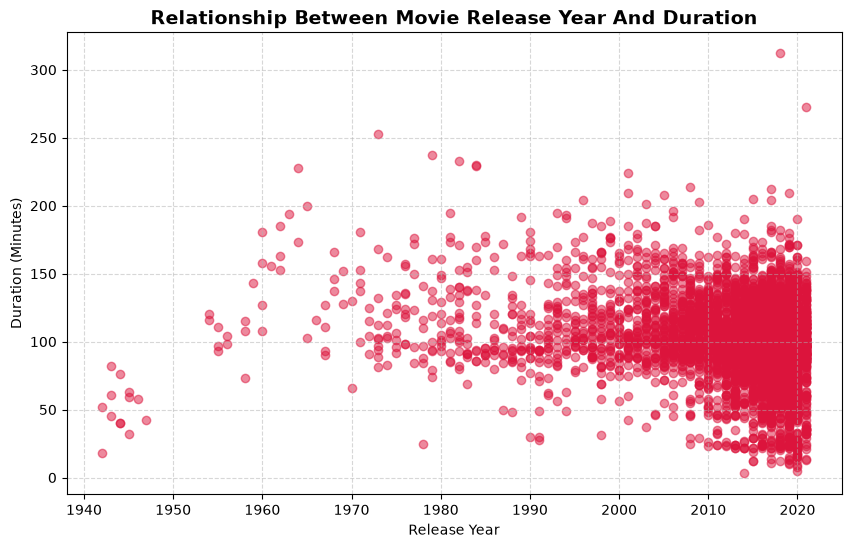

In [33]:
df = pd.read_csv("netflix_titles.csv")
movies = df[df["type"] == "Movie"].copy()
movies["duration_num"] = pd.to_numeric(movies["duration"].str.extract(r"(\d+)")[0])
movies_clean = movies.dropna(subset=["release_year", "duration_num"])

plt.figure(figsize=(10,6))
plt.scatter(movies_clean["release_year"], movies_clean["duration_num"], alpha=0.5, color="crimson")
plt.title("Relationship Between Movie Release Year And Duration", fontsize=14, fontweight="bold")
plt.xlabel("Release Year")
plt.ylabel("Duration (Minutes)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show

In [34]:
df

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...
...,...,...,...,...,...,...,...,...,...,...,...,...
8802,s8803,Movie,Zodiac,David Fincher,"Mark Ruffalo, Jake Gyllenhaal, Robert Downey J...",United States,"November 20, 2019",2007,R,158 min,"Cult Movies, Dramas, Thrillers","A political cartoonist, a crime reporter and a..."
8803,s8804,TV Show,Zombie Dumb,NaN,NaN,NaN,"July 1, 2019",2018,TV-Y7,2 Seasons,"Kids' TV, Korean TV Shows, TV Comedies","While living alone in a spooky town, a young g..."
8804,s8805,Movie,Zombieland,Ruben Fleischer,"Jesse Eisenberg, Woody Harrelson, Emma Stone, ...",United States,"November 1, 2019",2009,R,88 min,"Comedies, Horror Movies",Looking to survive in a world taken over by zo...
8805,s8806,Movie,Zoom,Peter Hewitt,"Tim Allen, Courteney Cox, Chevy Chase, Kate Ma...",United States,"January 11, 2020",2006,PG,88 min,"Children & Family Movies, Comedies","Dragged from civilian life, a former superhero..."


In [35]:
# 10 Who are the directors with the most Netflix titles?

<function matplotlib.pyplot.show(close=None, block=None)>

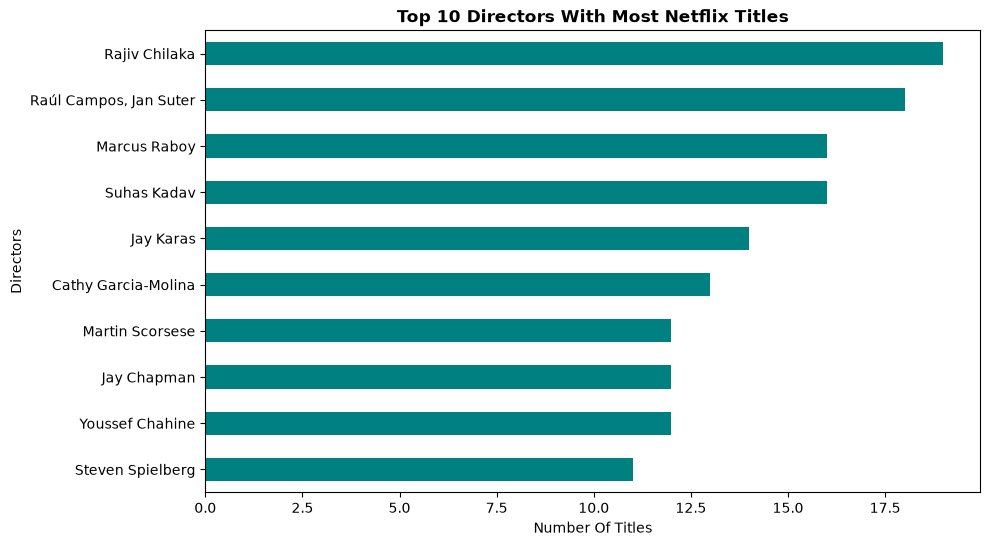

In [36]:
top_directors = df["director"].value_counts().head(10)

plt.figure(figsize=(10, 6))
top_directors.sort_values().plot(kind="barh", color="teal")

plt.title("Top 10 Directors With Most Netflix Titles", fontweight="bold")
plt.xlabel("Number Of Titles")
plt.ylabel("Directors")
plt.show

In [37]:
# 11 Which actors appear most frequently across Netflix titles?

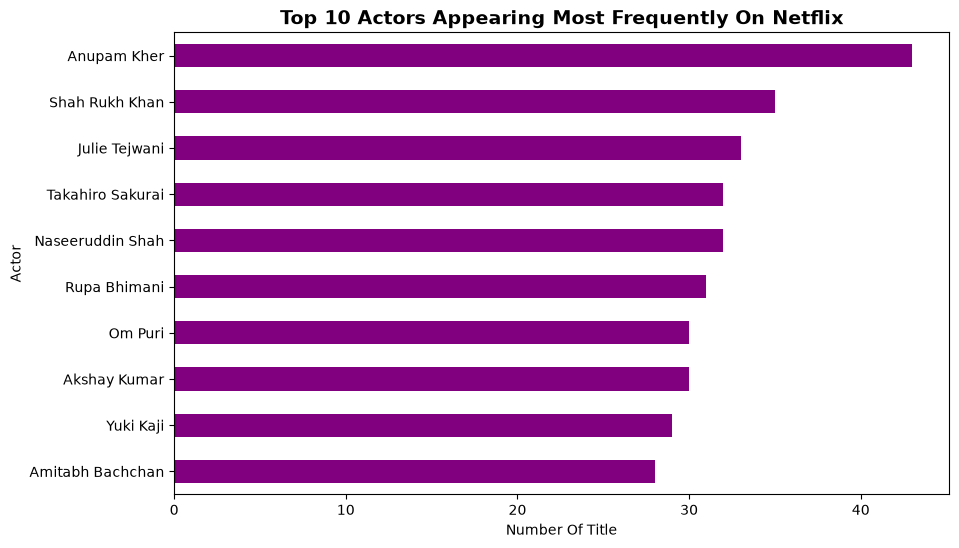

In [38]:
actors = df["cast"].dropna().str.split(", ").explode()
top_actors = actors = actors.value_counts().head(10)

plt.figure(figsize=(10, 6))
top_actors.sort_values().plot(kind="barh", color="purple")

plt.title("Top 10 Actors Appearing Most Frequently On Netflix", fontsize="14", fontweight="bold")
plt.xlabel("Number Of Title")
plt.ylabel("Actor")
plt.show()

In [39]:
# 12 How long after release are titles typically added to Netflix?

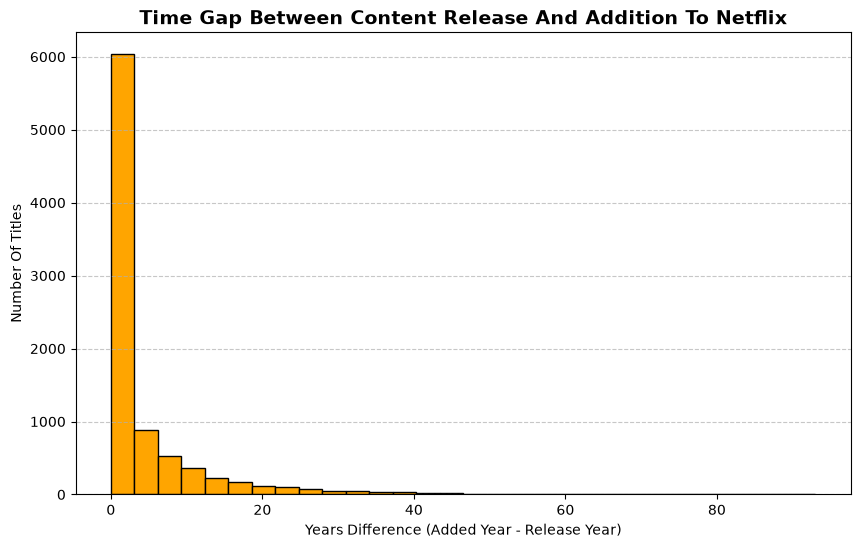

In [40]:
df["year_added"] = pd.to_datetime(df["date_added"].str.strip()).dt.year
df["years_to_add"] = df["year_added"] - df["release_year"]
clean_diff = df[df["years_to_add"] >= 0]["years_to_add"]

plt.figure(figsize=(10, 6))
plt.hist(clean_diff, bins=30, color="orange", edgecolor="black")
plt.title("Time Gap Between Content Release And Addition To Netflix", fontsize=14, fontweight="bold")
plt.xlabel("Years Difference (Added Year - Release Year)")
plt.ylabel("Number Of Titles")
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.show()

In [41]:
# 13 Which months see the most Netflix titles added?

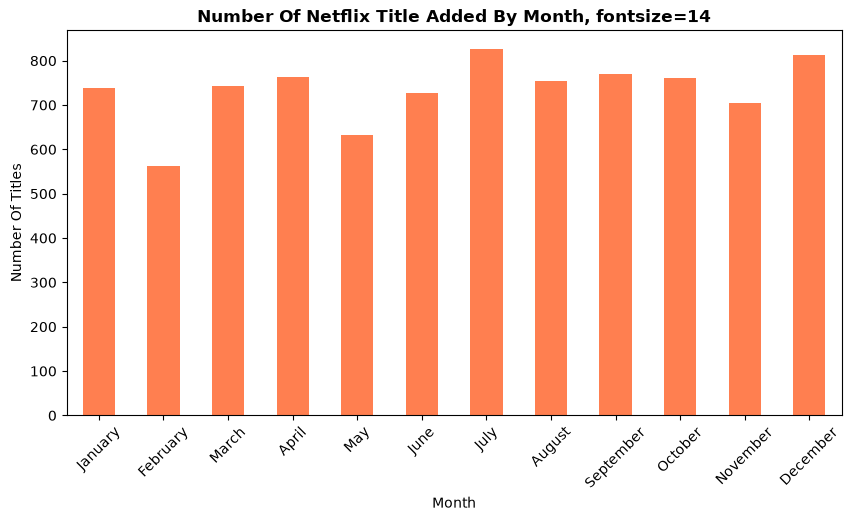

In [42]:
df["date_added"] = pd.to_datetime(df["date_added"].str.strip())
monthly_counts = df["date_added"].dt.month_name().value_counts()
months_order = ["January", "February", "March", "April", "May", "June", "July", "August", "September", "October", "November", "December"]
monthly_counts = monthly_counts.reindex(months_order)

plt.figure(figsize=(10, 5))
monthly_counts.plot(kind="bar", color="coral")
plt.title("Number Of Netflix Title Added By Month, fontsize=14", fontweight="bold")
plt.xlabel("Month")
plt.ylabel("Number Of Titles")
plt.xticks(rotation=45)
plt.show()

In [43]:
# 14 How does the distribution of ratings differ between Movies and TV Shows?

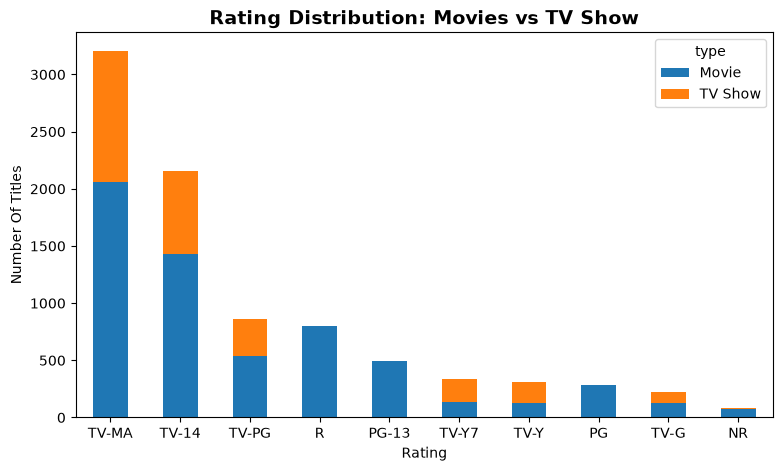

In [44]:
rating_counts = pd.crosstab(df["rating"], df["type"])
top_10_ratings = df["rating"].value_counts().head(10).index
rating_counts = rating_counts.loc[top_10_ratings]

rating_counts.plot(kind="bar", stacked=True, figsize=(9, 5))
plt.title("Rating Distribution: Movies vs TV Show", fontsize=14, fontweight="bold")
plt.xlabel("Rating")
plt.ylabel("Number Of Titles")
plt.xticks(rotation=0)
plt.show()

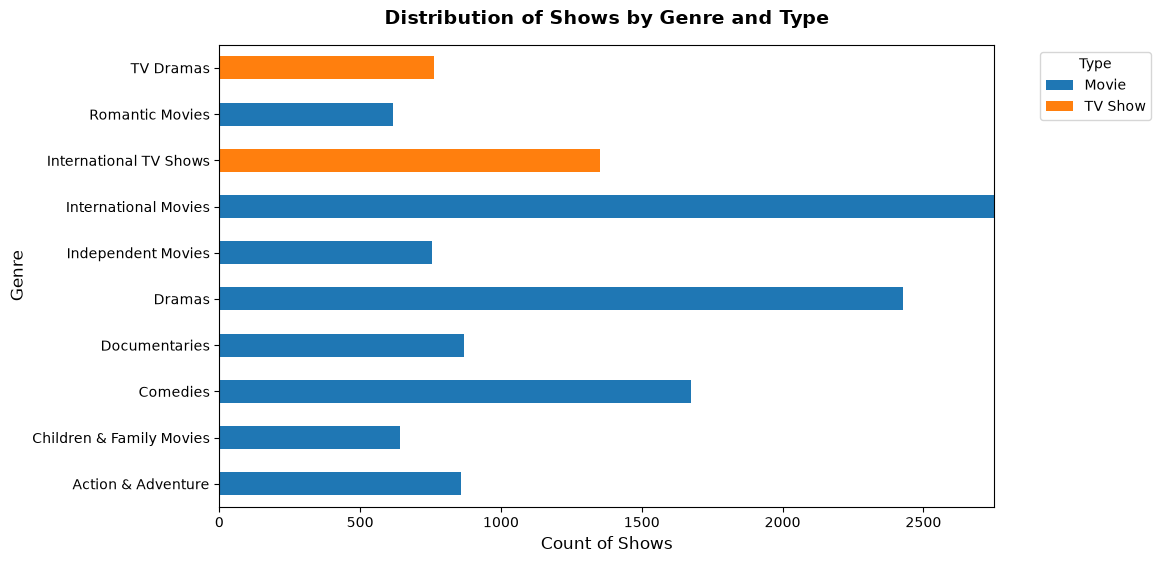

In [61]:
df_exploded = df.assign(genre=df["listed_in"].str.split(", ")).explode("genre")
top_10_genres = df_exploded["genre"].value_counts().head(10).index
filtered_df = df_exploded[df_exploded["genre"].isin(top_10_genres)]
final = filtered_df.groupby(["genre", "type"])["show_id"].count().reset_index()
final


pivot_df = final.pivot(index='genre', columns='type', values='show_id')


ax = pivot_df.plot(kind='barh', stacked=True, figsize=(10, 6), color=['#1f77b4', '#ff7f0e'])

# 4. Clean up the formatting
plt.title('Distribution of Shows by Genre and Type', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Count of Shows', fontsize=12)
plt.ylabel('Genre', fontsize=12)
plt.legend(title='Type', bbox_to_anchor=(1.05, 1), loc='upper left')


plt.show()
# final.plot(kind="bar", stacked=True, figsize=(10, 5), color=["crimson", "darkblue"])
# plt.title("Top Genre: Movies vs TV Shows", fontsize=14, fontweight="bold")
# plt.xlabel("Genre")
# plt.ylabel("Number Of Title")
# plt.xticks(rotation=45)
# plt.show()